# Part 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces

## Step 1

In [2]:
class TreasureGridEnv(gym.Env):
    metadata = {"render_modes": ["human"]}
    
    def __init__(self, render_mode=None):
        super(TreasureGridEnv, self).__init__()
        self.n_rows = 5
        self.n_cols = 5
        self.n_states = self.n_rows * self.n_cols
        self.n_actions = 4 
        self.action_space = spaces.Discrete(self.n_actions)
        self.observation_space = spaces.Discrete(self.n_states)
        self.reward_grid = -1 * np.ones((self.n_rows, self.n_cols), dtype=float)
        self.goal_pos = (4, 4)
        self.reward_grid[self.goal_pos] = 10.0
        self.bonus_pos = (2, 3)
        self.reward_grid[self.bonus_pos] = 5.0
        self.trap_positions = [(1, 3), (3, 1)]
        for (r, c) in self.trap_positions:
            self.reward_grid[r, c] = -10.0
        self.mud_positions = [(2, 1), (3, 3)]
        for (r, c) in self.mud_positions:
            self.reward_grid[r, c] = -3.0
        self.start_pos = (0, 0)
        self.max_steps = 50
        self.current_step = 0
        self.agent_pos = None
        self.render_mode = render_mode

    def _pos_to_state(self, pos):
        r, c = pos
        return r * self.n_cols + c

    def _state_to_pos(self, state):
        r = state // self.n_cols
        c = state % self.n_cols
        return (r, c)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.agent_pos = self.start_pos
        self.current_step = 0
        obs = self._pos_to_state(self.agent_pos)
        info = {}
        return obs, info

    def step(self, action):
        self.current_step += 1
        r, c = self.agent_pos
        if action == 0:   
            r -= 1
        elif action == 1: 
            r += 1
        elif action == 2: 
            c -= 1
        elif action == 3: 
            c += 1
        r = np.clip(r, 0, self.n_rows - 1)
        c = np.clip(c, 0, self.n_cols - 1)
        self.agent_pos = (r, c)
        reward = self.reward_grid[r, c]
        terminated = False
        if self.agent_pos == self.goal_pos or self.agent_pos in self.trap_positions:
            terminated = True
        truncated = self.current_step >= self.max_steps
        obs = self._pos_to_state(self.agent_pos)
        info = {}
        return obs, reward, terminated, truncated, info

    def render(self):
        grid_symbols = np.full((self.n_rows, self.n_cols), ".", dtype=object)
        grid_symbols[self.goal_pos] = "G"   
        grid_symbols[self.bonus_pos] = "B" 
        for (r, c) in self.trap_positions:
            grid_symbols[r, c] = "X"
        for (r, c) in self.mud_positions:
            if grid_symbols[r, c] == ".":
                grid_symbols[r, c] = "M"  
        ar, ac = self.agent_pos
        grid_symbols[ar, ac] = "A"
        print("Current grid:")
        for r in range(self.n_rows):
            row_str = " ".join(grid_symbols[r, :])
            print(row_str)
        print()

## Step 2 & 3

In [3]:
env = TreasureGridEnv()
obs, info = env.reset()
print("Initial state:", obs)
env.render()

Initial state: 0
Current grid:
A . . . .
. . . X .
. M . B .
. X . M .
. . . . G



In [4]:
n_steps = 10
for t in range(n_steps):
    action = env.action_space.sample()
    next_obs, reward, terminated, truncated, info = env.step(action)
    print(f"Step {t+1}")
    print("  Current state:", obs)
    print("  Action taken:", action)
    print("  Reward:", reward)
    print("  Next state:", next_obs)
    print()
    env.render()
    obs = next_obs
    if terminated or truncated:
        print("Episode ended.\n")
        obs, info = env.reset()
        env.render()

Step 1
  Current state: 0
  Action taken: 2
  Reward: -1.0
  Next state: 0

Current grid:
A . . . .
. . . X .
. M . B .
. X . M .
. . . . G

Step 2
  Current state: 0
  Action taken: 1
  Reward: -1.0
  Next state: 5

Current grid:
. . . . .
A . . X .
. M . B .
. X . M .
. . . . G

Step 3
  Current state: 5
  Action taken: 3
  Reward: -1.0
  Next state: 6

Current grid:
. . . . .
. A . X .
. M . B .
. X . M .
. . . . G

Step 4
  Current state: 6
  Action taken: 2
  Reward: -1.0
  Next state: 5

Current grid:
. . . . .
A . . X .
. M . B .
. X . M .
. . . . G

Step 5
  Current state: 5
  Action taken: 2
  Reward: -1.0
  Next state: 5

Current grid:
. . . . .
A . . X .
. M . B .
. X . M .
. . . . G

Step 6
  Current state: 5
  Action taken: 1
  Reward: -1.0
  Next state: 10

Current grid:
. . . . .
. . . X .
A M . B .
. X . M .
. . . . G

Step 7
  Current state: 10
  Action taken: 1
  Reward: -1.0
  Next state: 15

Current grid:
. . . . .
. . . X .
. M . B .
A X . M .
. . . . G

Step 8
  C

## Step 4

**Environment Description**

Scenario – “Treasure Hunt Grid World”
I created a 5×5 grid where the agent is an explorer trying to reach a treasure.
There are traps, mud tiles, and one bonus tile. The environment is small but still has enough variation for meaningful RL learning.

**States**

25 states (from (0,0) to (4,4)).
Each state is stored as an integer 0–24.

**Actions**

0 = Up

1 = Down

2 = Left

3 = Right

**Rewards**

+10 → goal/treasure tile

+5 → bonus tile

–10 → trap

–3 → mud

–1 → normal movement


## Step 5

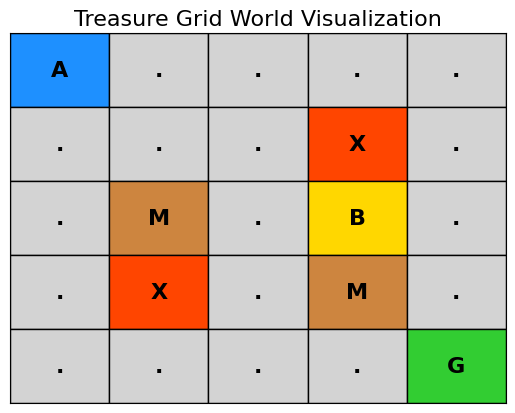

In [5]:
def visualize_env(env):
    fig, ax = plt.subplots()
    color_map = {"A": "#1E90FF",  "G": "#32CD32",  "B": "#FFD700",  "X": "#FF4500",  "M": "#CD853F",  ".": "#D3D3D3"}
    grid = np.full((env.n_rows, env.n_cols), ".", dtype=str)
    grid[env.goal_pos] = "G"
    grid[env.bonus_pos] = "B"
    for pos in env.trap_positions:
        grid[pos] = "X"
    for pos in env.mud_positions:
        grid[pos] = "M"
    ar, ac = env.agent_pos
    grid[ar, ac] = "A"
    for r in range(env.n_rows):
        for c in range(env.n_cols):
            rect = plt.Rectangle((c, env.n_rows - 1 - r), 1, 1, facecolor=color_map[grid[r, c]], edgecolor="black")
            ax.add_patch(rect)
            ax.text(c + 0.5, env.n_rows - 1 - r + 0.5, grid[r, c], ha="center", va="center", fontsize=16, fontweight="bold")
    ax.set_xlim(0, env.n_cols)
    ax.set_ylim(0, env.n_rows)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title("Treasure Grid World Visualization", fontsize=16)
    plt.show()
env = TreasureGridEnv()
env.reset()
visualize_env(env)


**Visualization Description**

I used a printed grid where:

A = Agent

G = Main treasure

B = Bonus

X = Trap

M = Mud

. = Normal tile

The grid prints after every step so I can visually check movement and state transitions.

## Step 6

**Safety in AI Review**

~ I ensured safety in my environment by checking all actions against the allowed action set, so the agent never executes an invalid action.  
~ The boundaries are clipped, which prevents the agent from moving outside the grid.  
~ Rewards are predefined and fixed to avoid unexpected behavior.  
~ The environment terminates episodes when a goal or trap is reached, preventing infinite loops.  
~ I also reset the agent properly each time to make sure every episode starts in a known and safe position.  


## Step 7

### Contribution Table :

### Team Contribution Summary

| Step | Teammate | Contribution % |
|------|----------|----------------|
| 1 | pranayla & sramavar | each 50% |
| 2 | pranayla & sramavar | each 50% |
| 3 | pranayla & sramavar | each 50% |
| 4 | pranayla & sramavar | each 50% |
| 5 | pranayla & sramavar | each 50% |
| 6 | pranayla & sramavar | each 50% |